# S08 · Прогноз победы в Counter-Strike

23 октября 2026. Выполняйте ячейки сверху вниз с чистого ядра. В каждом разделе напишите целую ячейку по условию.

## C01 · Инструменты

Импортируйте CSV, пути, графики, NumPy и PyTorch. Для повторения одинакового запуска заранее выберите один поток CPU и генератор 8: он фиксирует начальные случайные веса.

In [1]:
# S08-C01
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

torch.set_num_threads(1)
torch.manual_seed(8)

## C02 · Читаем матчи и находим DETONA - Denial

Прочитайте локальный data/csgo-match-features.csv. Найдите матч с match_id="2332375": DETONA против Denial. Покажите команды и их предыдущие победы. BO3 означает серию до двух выигранных карт. [Данные и отбор](../data/CSGO-README.md).

In [2]:
# S08-C02
folder = Path.cwd()
if folder.name == "solutions":
    folder = folder.parent
if folder.name == "notebooks":
    folder = folder.parent
if folder.name != "starter":
    folder = folder / "starter"
with (folder / "data/csgo-match-features.csv").open() as file:
    rows = list(csv.DictReader(file))
print("Матчей в файле:", len(rows))
for example_index, row in enumerate(rows):
    if row["match_id"] == "2332375":
        break
example = rows[example_index]
print(example["team1"], "против", example["team2"])
print("Предыдущие победы из 10:", example["wins1_last10"], example["wins2_last10"])

Матчей в файле: 7843
DETONA против Denial
Предыдущие победы из 10: 8 6


## C03 · Два признака и правильный ответ

Для каждой команды возьмите число побед в последних 10 допустимых предыдущих матчах и разделите на 10. Подготовленная история использует только результаты матчей, начавшихся более чем за сутки до decision_at. Цель team1_won: 1 = победила первая команда, 0 = вторая. В конце покажите features[example_index] для найденного матча DETONA - Denial. Его фактический исход до решения не печатайте.

In [4]:
# S08-C03
features = []
targets = []
for row in rows:
    features.append([int(row["wins1_last10"]) / 10, int(row["wins2_last10"]) / 10])
    targets.append(int(row["team1_won"]))
X = torch.tensor(features, dtype=torch.float32)
y = torch.tensor(targets, dtype=torch.float32).reshape(-1, 1)
print(X.shape, y.shape)
print("Вход DETONA - Denial:", features[example_index])

torch.Size([7843, 2]) torch.Size([7843, 1])
Вход DETONA - Denial: [0.8, 0.6]


## C04 · Разделение по времени

По столбцу split соберите индексы train, validation и test. Передайте их таблицам X и y. Разбиение заранее зафиксировано в CSV: обучение на матчах 2016-2018 годов, проверка настроек в начале 2019 года, итоговая проверка с 25 апреля по 7 июля 2019 года. Не перемешивайте календарь.

In [5]:
# S08-C04
train_ids = [i for i, row in enumerate(rows) if row["split"] == "train"]
validation_ids = [i for i, row in enumerate(rows) if row["split"] == "validation"]
test_ids = [i for i, row in enumerate(rows) if row["split"] == "test"]
X_train, y_train = X[train_ids], y[train_ids]
X_validation, y_validation = X[validation_ids], y[validation_ids]
X_test, y_test = X[test_ids], y[test_ids]
test_rows = [rows[i] for i in test_ids]
print("train / validation / test:", len(train_ids), len(validation_ids), len(test_ids))

train / validation / test: 6218 952 673


## C05 · Небольшая сеть

Два входа содержат доли прошлых побед. Выберите заранее 8 скрытых нейронов и 1 выход z: Linear(2,8), ReLU, Linear(8,1). Сигмоида превратит z в оценку победы первой команды. Для обучения используйте BCEWithLogitsLoss: знакомую бинарную логарифмическую потерю со встроенной сигмоидой. SGD меняет параметры по производным; шаг заранее равен 0.5. Постоянный ориентир baseline_probability равен доле побед первой команды только на train.

In [6]:
# S08-C05
baseline_probability = y_train.mean().item()
model = nn.Sequential(nn.Linear(2, 8), nn.ReLU(), nn.Linear(8, 1))
loss_function = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.5)
print("Постоянная оценка:", round(baseline_probability, 4))
print("Параметров:", sum(parameter.numel() for parameter in model.parameters()))

Постоянная оценка: 0.5404
Параметров: 33


## C06 · Обучение

Повторите 500 заранее выбранных шагов на 6218 обучающих матчах. zero_grad очищает старые производные; model вычисляет z; loss_function сравнивает z с известными исходами; backward находит производные; step меняет веса. Сохраните среднюю логарифмическую потерю, напечатайте шаги 1, 100 и 500 и постройте график.

1 0.709096
100 0.677812
500 0.668636


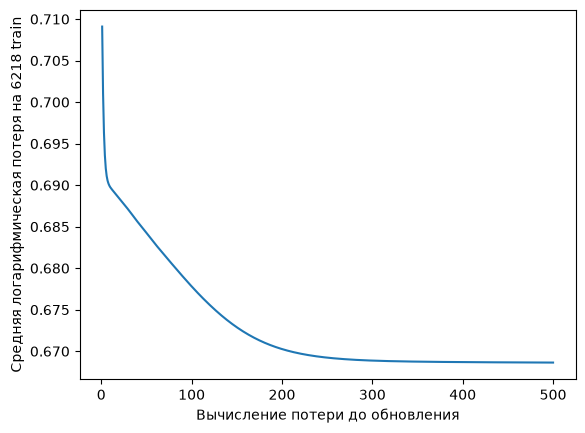

In [7]:
# S08-C06

history = []
for step in range(500):
    optimizer.zero_grad()
    logits = model(X_train)
    loss = loss_function(logits, y_train)
    loss.backward()
    optimizer.step()
    history.append(loss.item())
    if step in [0, 99, 499]:
        print(step + 1, round(loss.item(), 6))
plt.plot(range(1, 501), history)
plt.xlabel("Вычисление потери до обновления")
plt.ylabel("Средняя логарифмическая потеря на 6218 train")
plt.show()

## C07 · Что выучила сеть

У сети всего два входа, и каждый принимает только 11 значений: 0, 0.1, ..., 1. Значит, можно перебрать все 11 x 11 = 121 сочетание и нарисовать ответ сети для каждого. Покажите 8 скрытых нейронов (их значения после ReLU) и итоговую оценку p. По вертикали доля побед первой команды, по горизонтали второй. Точка отмечает DETONA - Denial: [0.8, 0.6].

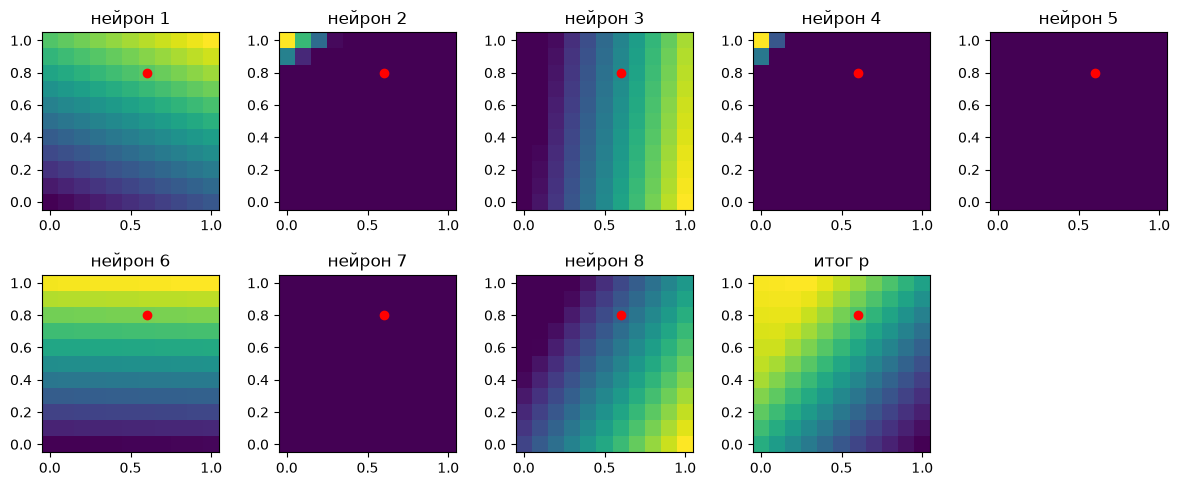

p для [0.8, 0.6]: 0.6153


In [8]:
# S08-C07
shares = torch.arange(11) / 10
grid = torch.cartesian_prod(shares, shares)
with torch.no_grad():
    hidden = torch.relu(model[0](grid))
    surface = torch.sigmoid(model(grid))
plt.figure(figsize=(12, 5))
for i in range(9):
    plt.subplot(2, 5, i + 1)
    values = hidden[:, i] if i < 8 else surface[:, 0]
    plt.imshow(values.reshape(11, 11), origin="lower", extent=[-0.05, 1.05, -0.05, 1.05], cmap="viridis")
    plt.scatter([0.6], [0.8], color="red")
    plt.title("нейрон " + str(i + 1) if i < 8 else "итог p")
plt.tight_layout()
plt.show()
print("p для [0.8, 0.6]:", round(surface[8 * 11 + 6, 0].item(), 4))

## C08 · Проверка вероятностей: ручной пример и новые матчи

Доля угаданных победителей не различает осторожный и уверенный прогноз. Для двух условных исходов [1,0] сравните прогнозы [0.6,0.6] и [0.9,0.9]: обе пары угадывают 1 матч из 2. Средний квадрат ошибки вероятности, Brier Score, равен $\sum(p-y)^2/n$; меньше лучше. Затем получите p через sigmoid на 952 validation-матчах и сравните сеть с постоянной train-частотой. Печатайте сумму квадратов и число матчей.

In [10]:
# S08-C08
example_actual = np.array([1, 0])
forecast_60 = np.array([0.6, 0.6])
forecast_90 = np.array([0.9, 0.9])
print("Учебные 2 матча, прогнозы 60%:", round(float(((forecast_60 - example_actual) ** 2).mean()), 2))
print("Учебные 2 матча, прогнозы 90%:", round(float(((forecast_90 - example_actual) ** 2).mean()), 2))

with torch.no_grad():
    validation_p = torch.sigmoid(model(X_validation)).flatten().numpy()

validation_actual = y_validation.flatten().numpy()
validation_squared = (validation_p - validation_actual) ** 2
print("validation n:", len(validation_p))
print("Сумма квадратов:", float(validation_squared.sum()))
print("Brier:", float(validation_squared.mean()))
print("Brier постоянной оценки:", float(((baseline_probability - validation_actual) ** 2).mean()))

Учебные 2 матча, прогнозы 60%: 0.26
Учебные 2 матча, прогнозы 90%: 0.41
validation n: 952
Сумма квадратов: 217.7672882080078
Brier: 0.2287471443414688
Brier постоянной оценки: 0.24399708211421967


## C09 · Выплата, ожидаемый результат и правило отбора

В условном примере ставка равна 1, коэффициент k=1.5, вероятность p=0.6. Победа приносит чистые +0.5, поражение -1; ожидаемый результат $0.6\cdot0.5+0.4\cdot(-1)=-0.1$. То же выражение равно p*k-1. Затем заранее зафиксируйте: stake=1, initial_bank=1000, minimum_expected_profit=0.05. В этом упрощённом опыте выбираем только между ставкой на первую команду и пропуском.

In [11]:
# S08-C09
stake = 1.0
initial_bank = 1000.0
minimum_expected_profit = 0.05
example_p = 0.6
example_odds = 1.5
print("Ожидание на единицу по выбранной p:", round(example_p * example_odds - 1, 3))


Ожидание на единицу по выбранной p: -0.1


## C10 · Открываем последние матчи

Проверьте готовую сеть на 673 более поздних матчах и сравните с простым правилом «всегда первая команда». test_p[i] означает оценку победы team1 для test_rows[i]. Вероятность team2 равна 1-test_p[i]. Для подсчёта угаданных победителей выбираем первую команду при p>=0.5. Для сравнения вероятностей усредняем квадраты (p-y)^2. Все настройки и правило условных ставок уже зафиксированы.

In [12]:
# S08-C10
with torch.no_grad():
    test_p = torch.sigmoid(model(X_test)).flatten().numpy()
actual = y_test.flatten().numpy()
squared = (test_p - actual) ** 2
correct = int(((test_p >= 0.5) == actual).sum())
print("Верных исходов:", correct, "/", len(test_p))
print("Если всегда называть первую команду:", int(actual.sum()), "/", len(actual))
print("Сумма квадратов:", float(squared.sum()))
print("Brier сети:", float(squared.mean()))
print("Brier постоянной оценки:", float(((baseline_probability - actual) ** 2).mean()))

Верных исходов: 402 / 673
Если всегда называть первую команду: 360 / 673
Сумма квадратов: 161.414306640625
Brier сети: 0.23984295129776
Brier постоянной оценки: 0.24881036579608917


## C11 · Два матча: вероятности и явное решение

Отберите 164 test-матча с архивными коэффициентами. Разберите записи с позициями 0 и 6: DETONA - Denial и Valiance - Vitality. Индексы выбраны только для показа двух примеров; общий цикл C11 проверит все строки. Печатайте названия, p1, p2=1-p1, коэффициент первой команды, ожидаемый чистый результат p1*k-1 и решение. Рассматриваем только «1 на team1» либо «пропуск» при пороге 0.05. Исход матча при выборе не читаем.

In [13]:
# S08-C11
quoted_rows = []
quoted_p = []
for position, row in enumerate(test_rows):
    if row["odds1"]:
        quoted_rows.append(row)
        quoted_p.append(test_p[position])
print("Матчей с коэффициентами:", len(quoted_rows))
for position in [0, 6]:
    example = quoted_rows[position]
    p1 = float(quoted_p[position])
    p2 = 1 - p1
    odds = float(example["odds1"])
    expected_profit = p1 * odds - 1
    print(example["team1"], "vs", example["team2"])
    print("Оценка победы", example["team1"], ":", round(p1 * 100, 2), "%")
    print("Оценка победы", example["team2"], ":", round(p2 * 100, 2), "%")
    print("Коэффициент на", example["team1"], ":", odds)
    print("Ожидаемый чистый результат на 1:", round(expected_profit, 4))
    if expected_profit > minimum_expected_profit:
        print("Решение: ставка 1 на", example["team1"])
    else:
        print("Решение: пропуск")

Матчей с коэффициентами: 164
DETONA vs Denial
Оценка победы DETONA : 61.53 %
Оценка победы Denial : 38.47 %
Коэффициент на DETONA : 1.15
Ожидаемый чистый результат на 1: -0.2924
Решение: пропуск
Valiance vs Vitality
Оценка победы Valiance : 48.99 %
Оценка победы Vitality : 51.01 %
Коэффициент на Valiance : 2.31
Ожидаемый чистый результат на 1: 0.1317
Решение: ставка 1 на Valiance


## C12 · Все ставки: команда, прогноз и фактический результат

Примените то же правило ко всем 164 матчам. Рассчитываем ожидаемый результат probability*odds-1; при значении больше 0.05 ставим 1 на row["team1"]. Только после выбора читаем outcome: 1 = эта команда победила, 0 = проиграла. Чистый фактический итог stake*(odds*outcome-1). Для первых трёх выбранных ставок напечатайте команды, на кого поставили и сколько получили. Затем общий итог и число ставок.

In [14]:
# S08-C12
bank = initial_bank
bank_history = [bank]
bet_count = 0
bet_wins = 0
for row, probability in zip(quoted_rows, quoted_p):
    odds = float(row["odds1"])
    expected_profit = float(probability) * odds - 1
    if expected_profit > minimum_expected_profit:
        outcome = int(row["team1_won"])
        profit = stake * (odds * outcome - 1)
        bank = bank + profit
        bet_count = bet_count + 1
        bet_wins = bet_wins + outcome
        if bet_count <= 3:
            print("Ставка на", row["team1"], "против", row["team2"])
            print("Оценка победы:", round(float(probability) * 100, 2), "%", "чистый итог:", round(profit, 2))
    bank_history.append(bank)
print("Ставок:", bet_count, "выиграно:", bet_wins)
print("Чистый итог:", round(bank - initial_bank, 2))
if bet_count > 0:
    print("Итог / сумма ставок:", round((bank - initial_bank) / (stake * bet_count), 4))

Ставка на Valiance против Vitality
Оценка победы: 48.99 % чистый итог: -1.0
Ставка на INTZ против Cloud9
Оценка победы: 58.59 % чистый итог: 1.57
Ставка на Tricked против Epsilon
Оценка победы: 53.67 % чистый итог: 1.06
Ставок: 63 выиграно: 26
Чистый итог: 0.58
Итог / сумма ставок: 0.0092


## C13 · График условного итога

Постройте bank_history: накопленный условный итог после рассмотрения каждого матча с коэффициентом. При пропуске ставки значение не меняется. Горизонтальная линия initial_bank показывает выбранные 1000 единиц. Ось X считает матчи, а не минуты реального счёта.

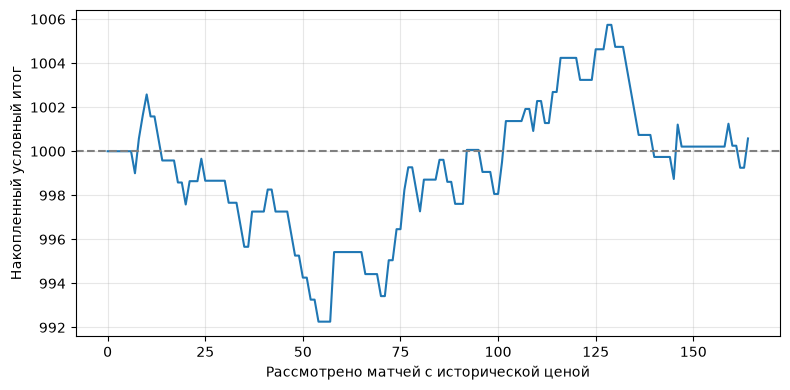

In [15]:
# S08-C13
plt.figure(figsize=(8, 4))
plt.plot(bank_history)
plt.axhline(initial_bank, color="gray", linestyle="--")
plt.xlabel("Рассмотрено матчей с исторической ценой")
plt.ylabel("Накопленный условный итог")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## C14 · Сравнение сети с оценкой из коэффициентов

Коэффициенты тоже несут информацию о силах команд. Получим простой ориентир: q1=(1/k1)/(1/k1+1/k2). Для DETONA - Denial k1=1.15 и k2=4.84, поэтому q1 примерно 0.8080. Деление на сумму делает оценки двух команд суммарно равными 1; истинную вероятность такой расчёт не гарантирует. На тех же 164 матчах сравните средний квадрат ошибки сети и этого ориентира, а также число угаданных победителей.

In [16]:
# S08-C14
market_p = []
quoted_actual = []
for row in quoted_rows:
    inverse1 = 1 / float(row["odds1"])
    inverse2 = 1 / float(row["odds2"])
    market_p.append(inverse1 / (inverse1 + inverse2))
    quoted_actual.append(int(row["team1_won"]))
market_p = np.array(market_p)
quoted_actual = np.array(quoted_actual)
print("Одинаковых матчей:", len(quoted_actual))
print("Brier сети:", float(((np.array(quoted_p) - quoted_actual) ** 2).mean()))
print("Brier оценки из цен:", float(((market_p - quoted_actual) ** 2).mean()))
print("Угадано сетью:", int(((np.array(quoted_p) >= 0.5) == quoted_actual).sum()), "/", len(quoted_actual))
print("Угадано фаворитом букмекера:", int(((market_p >= 0.5) == quoted_actual).sum()), "/", len(quoted_actual))

Одинаковых матчей: 164
Brier сети: 0.2477670012325283
Brier оценки из цен: 0.23216891146072666
Угадано сетью: 94 / 164
Угадано фаворитом букмекера: 94 / 164
